In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\teleco_dataset_formatted.csv")
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


In [3]:
# The data types of all the columns have been formatted to proper data types.

# Check for missing values

df.isna().sum()

gender                                   0
SeniorCitizen                            0
Partner                                  0
Dependents                               0
tenure                                   0
PhoneService                             0
MultipleLines                            0
OnlineSecurity                           0
OnlineBackup                             0
DeviceProtection                         0
TechSupport                              0
StreamingTV                              0
StreamingMovies                          0
PaperlessBilling                         0
MonthlyCharges                           0
TotalCharges                             0
Churn                                    0
InternetService_Fiber optic              0
InternetService_No                       0
Contract_One year                        0
Contract_Two year                        0
PaymentMethod_Credit card (automatic)    0
PaymentMethod_Electronic check           0
PaymentMeth

No NULL values found.

In [4]:
print(df.duplicated().sum())

22


Since we dropped the CustomerID column, some rows can be duplicated, which we will not drop.

In [8]:
df[["MonthlyCharges", "TotalCharges", "tenure"]].describe()

,MonthlyCharges,TotalCharges,tenure
count,7043.000000,7043.000000,7043.000000
mean,64.761692,2279.734304,32.371149
std,30.090047,2266.794470,24.559481
min,18.250000,0.000000,0.000000
25%,35.500000,398.550000,9.000000
50%,70.350000,1394.550000,29.000000
75%,89.850000,3786.600000,55.000000
max,118.750000,8684.800000,72.000000


Remaining columns are categorical, and these columns which contain continuous values, Monthly Charges and tenure seem within range. But Total Charges column has slightly potentially skewed values, due to the sudden jump from 75% quartile to max value. Let's check with a plot.

In [10]:
import matplotlib.pyplot as plt

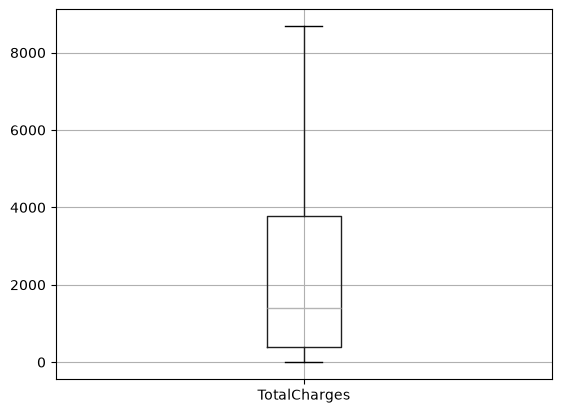

In [12]:
df.boxplot(column = ["TotalCharges"])
plt.show()

Based on the box plot, this column consists of data with right skewed distribution (since the median line is towards the 0). By applying log-transform, the skewness can be removed.

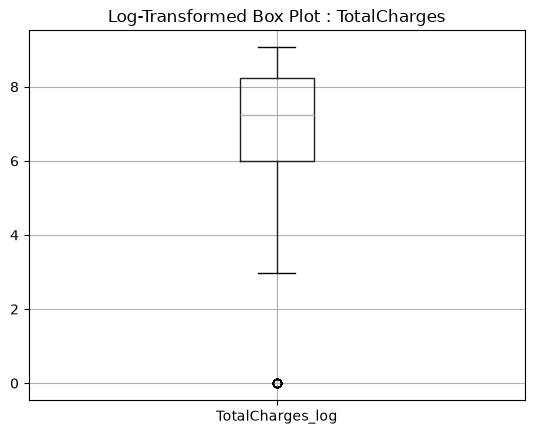

In [13]:
df["TotalCharges_log"] = np.log1p(df["TotalCharges"])

df.boxplot(column = ["TotalCharges_log"])
plt.title("Log-Transformed Box Plot : TotalCharges")
plt.show()

In [14]:
df.to_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\datasets\teleco_dataset_formatted_2.csv", index=False)